In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [18]:
df = pd.read_csv('Auto-mpg.csv')
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


In [62]:
from sklearn.linear_model import LinearRegression 
from sklearn.preprocessing import PolynomialFeatures 
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error,mean_absolute_percentage_error

In [4]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

In [19]:
# Features and target
X = df.drop(columns='mpg')
y = df['mpg']

# Remove Unwanted Characters

In [21]:
for col in X.columns:
    count = (X[col].astype(str) == '?').sum()
    if count > 0:
        print(col, count)

horsepower 6


In [23]:
(X['horsepower'].astype(str) == '?').sum()

6

In [24]:
for col in X.columns:
    if X[col].astype(str).str.contains(r'\?').any():
        print(col)

horsepower


In [25]:
for col in X.columns:
    if X[col].astype(str).str.contains(r'\?').any():
        X[col] = X[col].astype(str).replace('?', np.nan)
        

# Define Numerical and Categorical features

In [26]:
df['horsepower'] = pd.to_numeric(
    df['horsepower'],
    errors='coerce'
) 

# Numerical features
numeric_features = [
    'cylinders',
    'displacement',
    'horsepower',
    'weight',
    'acceleration',
    'model year'
]


In [27]:
# Categorical features
categorical_features = [
    'origin',
    'car name'
]

# Create Pipeline to Scale and Encode 

In [28]:
# Numerical pipeline
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [29]:
# Categorical pipeline
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Apply the transformations to numerical and categorical columns

In [30]:
# Preprocessor
X_numeric = numeric_pipeline.fit_transform(df[numeric_features])

df_reg = pd.DataFrame(X_numeric,columns = numeric_features,index = df.index)
df_reg

,cylinders,displacement,horsepower,weight,acceleration,model year
0,1.498191,1.090604,0.673118,0.630870,-1.295498,-1.627426
1,1.498191,1.503514,1.589958,0.854333,-1.477038,-1.627426
2,1.498191,1.196232,1.197027,0.550470,-1.658577,-1.627426
3,1.498191,1.061796,1.197027,0.546923,-1.295498,-1.627426
4,1.498191,1.042591,0.935072,0.565841,-1.840117,-1.627426
...,...,...,...,...,...,...
393,-0.856321,-0.513026,-0.479482,-0.213324,0.011586,1.621983
394,-0.856321,-0.925936,-1.370127,-0.993671,3.279296,1.621983
395,-0.856321,-0.561039,-0.531873,-0.798585,-1.440730,1.621983
396,-0.856321,-0.705077,-0.662850,-0.408411,1.100822,1.621983


In [31]:
X_categorical = categorical_pipeline.fit_transform(
    df[categorical_features]
)

In [32]:
#Retrieve column names and convert into dataframe
X_categorical_columns = (
    categorical_pipeline
    .named_steps['onehot']
    .get_feature_names_out(categorical_features)
)

X_categorical_df = pd.DataFrame(
    X_categorical.toarray(),
    columns=X_categorical_columns,
    index=df.index
)

In [33]:
df_ml = pd.concat(
    [
        df_reg,
        X_categorical_df,
        df[['mpg']]
    ],
    axis=1
)

In [34]:
df_ml.head()

,cylinders,displacement,horsepower,weight,acceleration,model year,origin_1,origin_2,origin_3,car name_amc ambassador brougham,...,car name_volvo 244dl,car name_volvo 245,car name_volvo 264gl,car name_volvo diesel,car name_vw dasher (diesel),car name_vw pickup,car name_vw rabbit,car name_vw rabbit c (diesel),car name_vw rabbit custom,mpg
0,1.498191,1.090604,0.673118,0.630870,-1.295498,-1.627426,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,18.0
1,1.498191,1.503514,1.589958,0.854333,-1.477038,-1.627426,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,15.0
2,1.498191,1.196232,1.197027,0.550470,-1.658577,-1.627426,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,18.0
3,1.498191,1.061796,1.197027,0.546923,-1.295498,-1.627426,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,16.0
4,1.498191,1.042591,0.935072,0.565841,-1.840117,-1.627426,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,17.0


In [35]:
df_ml.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Columns: 315 entries, cylinders to mpg
dtypes: float64(315)
memory usage: 979.6 KB


# To apply poly regression we have to convert first the X_train and test into polynomial 

### However before doing that we will need to find the best number of degrees for our Ply regresison

In [ ]:
MAE = []
RMSE = []

for d in range(1,10):
    poly_converter = PolynomialFeatures(degree = d,include_bias=True) # call the Poly Converter with degree in range selected  

    # this step could be done earlier but after Encoding the amount of column can make the iteration eccessive so we kept the step before the encoding in the loop
    # Only select Numerics
    df1 = df.select_dtypes(include = 'number')  

    #Scaling and Nan Pipeline
    numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
        ])

    # Column Identification
    X_numeric = df1.columns

    # Pipeline Application
    X_num = numeric_pipeline.fit_transform(df1[X_numeric])

    #Conversion in Df
    df1 = pd.DataFrame(X_num,columns = X_numeric,index = df.index)

    #Features Idetfication    
    X = df1.drop(columns='mpg')
    y = df1['mpg']

    #Split
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=101)

    X_poly_train = poly_converter.fit_transform(X_train)
    X_poly_test = poly_converter.transform(X_test) # to avoid data leakage we always only transform the x_test

    model1 = LinearRegression()
    model1.fit(X_poly_train,y_train)

    poly_res = model1.predict(X_poly_test)

    MAE.append(mean_absolute_error(y_test,poly_res))
    RMSE.append(np.sqrt(mean_squared_error(y_test,poly_res)))

# The target is to Identify the degree where MAE and RMS are lower 

In [48]:
MAE, RMSE

([0.31772130624461553,
  0.25408260336031696,
  0.4350248628885892,
  11.104566456905962,
  2.584922776239591,
  2.6134447713703985,
  3.2263984545793374,
  4.88591728077571,
  11.57097128855888],
 [0.4203139821172366,
  0.3499325610070471,
  0.9753748665188493,
  29.32694171845205,
  5.360394558936507,
  6.327280446591445,
  10.738392322175555,
  15.75241007022302,
  52.801708712525105])

# Probably the best degree is 2

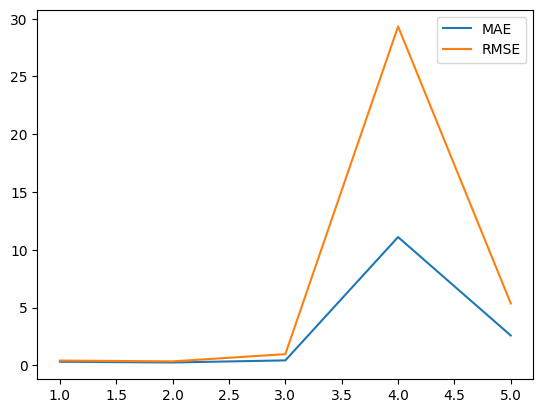

In [50]:
plt.plot(range(1,6),MAE[0:5],label='MAE')
plt.plot(range(1,6),RMSE[0:5],label='RMSE')
plt.legend()

# Model Implementation

## Feature Identification

In [52]:
X = df_ml.drop(columns = 'mpg')
y= df_ml['mpg']

## Train Test Split

In [53]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=101)

## Poly Convertr with degrees 2

In [54]:
poly_converter = PolynomialFeatures(degree = 2,include_bias=True)

## Fit of Poly_converter

In [55]:
X_poly_train = poly_converter.fit_transform(X_train)
X_poly_test = poly_converter.transform(X_test)

In [51]:
model = LinearRegression()

In [56]:
model.fit(X_poly_train,y_train)

LinearRegression()

In [57]:
res = model.predict(X_poly_test)

In [59]:
df_test = df.loc[X_test.index].drop(columns='mpg')

In [60]:
df_test['predicted_mpg'] = res
df_test

,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name,predicted_mpg
130,4,122.0,80.0,2451,16.5,74,1,ford pinto,20.885394
202,6,258.0,95.0,3193,17.8,76,1,amc pacer d/l,16.762300
322,4,86.0,65.0,2110,17.9,80,3,mazda glc,36.098334
104,8,400.0,167.0,4906,12.5,73,1,ford country,12.425503
91,8,400.0,150.0,4464,12.0,73,1,chevrolet caprice classic,12.206999
...,...,...,...,...,...,...,...,...,...
70,8,400.0,190.0,4422,12.5,72,1,chrysler newport royal,11.322234
195,4,85.0,52.0,2035,22.2,76,1,chevrolet chevette,21.618625
231,8,400.0,190.0,4325,12.2,77,1,chrysler cordoba,7.778554
90,8,429.0,198.0,4952,11.5,73,1,mercury marquis brougham,10.751568


In [63]:
MAE = mean_absolute_error(y_test,res)
MAPE = mean_absolute_percentage_error(y_test,res)

print(f'MAE{MAE},MAPE{MAPE}')

MAE2.8321364142045082,MAPE0.13090628477515073
